# 02 · Features derivadas — PSet #3

**Proyecto:** Churn de telecomunicaciones; origen `PSET2_CHURN.OBT.CUSTOMER_CHURN_OBT`.

**Objetivo:** validar con evidencia dos features del proyecto y su disponibilidad conceptual para inferencia. No entrenamos aquí ningún modelo ni ajustamos imputadores, codificadores o escaladores. Eso se hará dentro de `Pipeline` sobre entrenamiento/CV.

> **Límite temporal:** el dataset es transversal. No se puede demostrar con esta fuente que todas las variables se conocían antes de que ocurriera el abandono. Para producción se exigiría historial fechado de snapshots CRM. En el PSet #3 las estimaciones serán retrospectivas.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.datos import ORIGEN, leer_obt, variables_modelo, hash_snapshot
from src.pipeline import FeaturesDerivadas, NUMERICAS, CATEGORICAS, crear_preprocesador

OUT = Path('/workspace/docs')
OUT.mkdir(parents=True, exist_ok=True)
df = leer_obt()
X, y = variables_modelo(df)
assert df['CUSTOMER_ID'].is_unique
assert y.isin([0, 1]).all()
print('Origen:', ORIGEN)
print('Filas:', len(df), 'Hash:', hash_snapshot(df))

Origen: PSET2_CHURN.OBT.CUSTOMER_CHURN_OBT
Filas: 7043 Hash: d394e39192c935f813db937647ea608341131d5b3021696fbbb186daff7043d3


## 1. Construcción sin fuga de target

- **`MONTHLY_NEW_CUSTOMER`** = contrato mensual y antigüedad de hasta 12 meses. Motivación: en EDA el contrato mensual mostró 42,71 % de abandono frente a 2,83 % del contrato de dos años; comprobaremos la tasa para la interacción.
- **`SERVICE_BUNDLE_COUNT`** = número de servicios habilitados (`Yes`) entre seis productos de seguridad/soporte/streaming. Busca condensar el grado de vinculación del cliente con sus servicios. Es una hipótesis: la evidencia de asociación se mide aquí, **no** se presupone.

Ambas se construyen solo con columnas observadas en el snapshot, **sin usar `CHURN_FLAG`, `CUSTOMER_ID` ni `INGESTED_AT`**.

In [2]:
X_feat = FeaturesDerivadas().transform(X)
assert 'CUSTOMER_ID' not in X_feat
assert 'INGESTED_AT' not in X_feat
assert 'CHURN_FLAG' not in X_feat
assert 'NEW_CUSTOMER_WITHOUT_CHARGES' not in X_feat
assert X_feat[['MONTHLY_NEW_CUSTOMER','SERVICE_BUNDLE_COUNT']].isna().sum().sum() == 0
assert X_feat['SERVICE_BUNDLE_COUNT'].between(0,6).all()
assert X_feat['MONTHLY_NEW_CUSTOMER'].isin([0,1]).all()
assert len(X_feat) == len(df)
print('Predictores finales:', X_feat.shape[1])
display(X_feat[['CONTRACT','TENURE_MONTHS','MONTHLY_NEW_CUSTOMER','SERVICE_BUNDLE_COUNT']].head())

Predictores finales: 22


,CONTRACT,TENURE_MONTHS,MONTHLY_NEW_CUSTOMER,SERVICE_BUNDLE_COUNT
0,Month-to-month,1,1,1
1,One year,34,0,2
2,Month-to-month,2,1,2
3,One year,45,0,3
4,Month-to-month,2,1,0


## 2. Evidencia de la interacción contrato × antigüedad

Comparamos la tasa de abandono observada para el indicador nuevo. La comparación describe asociación, **no efecto causal**; la partición train/holdout posterior debe evitar usar esta exploración para reajustar hipótesis repetidamente.

,feature,clientes,abandonos,tasa,tasa_pct
0,0,5049,845,0.167360,16.74
1,1,1994,1024,0.513541,51.35


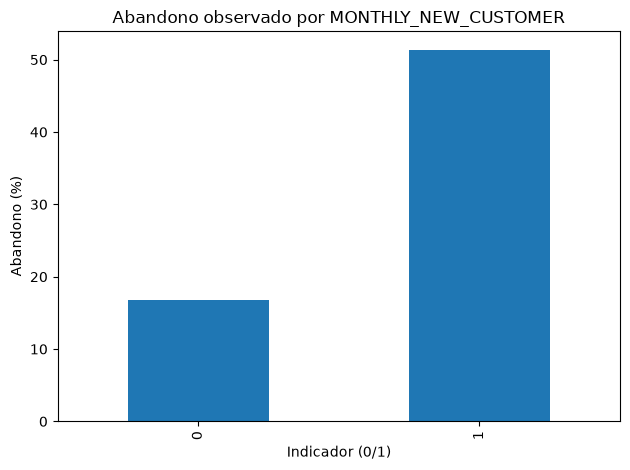

In [3]:
tabla_1 = pd.DataFrame({'feature': X_feat['MONTHLY_NEW_CUSTOMER'], 'churn': y}).groupby('feature')['churn'].agg(clientes='size', abandonos='sum', tasa='mean').reset_index()
tabla_1['tasa_pct'] = (tabla_1['tasa']*100).round(2)
display(tabla_1)
ax = tabla_1.plot.bar(x='feature', y='tasa_pct', legend=False, title='Abandono observado por MONTHLY_NEW_CUSTOMER')
ax.set(xlabel='Indicador (0/1)', ylabel='Abandono (%)')
plt.tight_layout(); plt.savefig(OUT/'feature_monthly_new_customer.png', dpi=150); plt.show()

## 3. Evidencia del número de servicios

Esta variable podría recoger una relación no lineal. Observaremos tamaños de grupo; si una cantidad tiene pocas observaciones, evitaremos sacar conclusiones fuertes.

,n_servicios,clientes,abandonos,tasa,tasa_pct
0,0,2219,475,0.214060,21.41
1,1,966,442,0.457557,45.76
2,2,1033,370,0.358180,35.82
3,3,1118,306,0.273703,27.37
4,4,852,190,0.223005,22.30
5,5,571,71,0.124343,12.43
6,6,284,15,0.052817,5.28


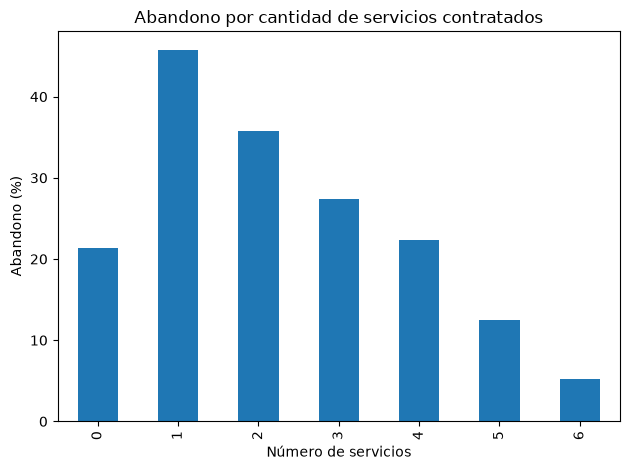

In [4]:
tabla_2 = pd.DataFrame({'n_servicios':X_feat['SERVICE_BUNDLE_COUNT'], 'churn':y}).groupby('n_servicios')['churn'].agg(clientes='size', abandonos='sum', tasa='mean').reset_index()
tabla_2['tasa_pct'] = (tabla_2['tasa']*100).round(2)
display(tabla_2)
ax = tabla_2.plot.bar(x='n_servicios', y='tasa_pct', legend=False, title='Abandono por cantidad de servicios contratados')
ax.set(xlabel='Número de servicios', ylabel='Abandono (%)')
plt.tight_layout(); plt.savefig(OUT/'feature_service_bundle_count.png', dpi=150); plt.show()

## 4. Duplicación de indicadores y preparación sin `fit`

En EDA, `TOTAL_CHARGES_MISSING` y `NEW_CUSTOMER_WITHOUT_CHARGES` fueron idénticas (correlación 1,00). Retenemos solo la primera, por parsimonia. `TOTAL_CHARGES` continúa con 11 nulos y se imputará **dentro de cada fold**. La codificación de categorías desconocidas se manejará con OneHotEncoder (`handle_unknown='ignore'`).

**Atención al posible leakage temporal:** cargos acumulados podría medirse después del evento en un sistema real; haremos un análisis de sensibilidad sin `TOTAL_CHARGES` al comparar modelos.

In [5]:
assert df['TOTAL_CHARGES_MISSING'].eq(df['NEW_CUSTOMER_WITHOUT_CHARGES']).all()
assert int(df['TOTAL_CHARGES'].isna().sum()) == 11
assert set(NUMERICAS + CATEGORICAS) == set(X_feat.columns), sorted(set(X_feat.columns) ^ set(NUMERICAS+CATEGORICAS))
prep = crear_preprocesador()
print('ColumnTransformer construido SIN entrenar:', type(prep).__name__)
print('Entradas numéricas:', NUMERICAS)
print('Entradas categóricas:', len(CATEGORICAS))
print('Ningún paso .fit() fue ejecutado en este notebook.')

ColumnTransformer construido SIN entrenar: ColumnTransformer
Entradas numéricas: ['SENIOR_CITIZEN', 'TENURE_MONTHS', 'MONTHLY_CHARGES', 'TOTAL_CHARGES', 'TOTAL_CHARGES_MISSING', 'MONTHLY_NEW_CUSTOMER', 'SERVICE_BUNDLE_COUNT']
Entradas categóricas: 15
Ningún paso .fit() fue ejecutado en este notebook.


## 5. Guardar evidencia y criterio para el informe

Solo describimos resultados reales del snapshot. No ajustamos el umbral comercial del 60 % con estas estadísticas, ni afirmamos haber demostrado efectividad de campañas.

In [6]:
resumen = {
  'origen': ORIGEN,
  'filas': int(len(df)),
  'hash_snapshot':hash_snapshot(df),
  'features': {
    'MONTHLY_NEW_CUSTOMER': {'explicacion':'Contrato mensual y TENURE_MONTHS <= 12', 'tabla':tabla_1.to_dict(orient='records')},
    'SERVICE_BUNDLE_COUNT':{'explicacion':'Suma de seis servicios con valor Yes', 'tabla':tabla_2.to_dict(orient='records')}
  },
  'columnas_para_modelar':X_feat.columns.tolist(),
  'drop_por_redundancia':'NEW_CUSTOMER_WITHOUT_CHARGES',
  'riesgo_temporal':'Disponibilidad previa al abandono no verificable por ausencia de historial fechado.',
  'plan':'Separación estratificada única y preprocessing dentro de Pipeline/ColumnTransformer en train/CV.'
}
with (OUT/'features_resumen.json').open('w',encoding='utf-8') as f:
    json.dump(resumen,f,indent=2,ensure_ascii=False)
print('Guardado:',OUT/'features_resumen.json')
print('Siguiente etapa: train/test estratificado UNA sola vez y evaluación CV en notebook 03.')

Guardado: /workspace/docs/features_resumen.json
Siguiente etapa: train/test estratificado UNA sola vez y evaluación CV en notebook 03.
